In [ ]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
 
# Input dataset
X = np.array(([2, 9], [1, 5], [3, 6]), dtype=float)
y = np.array([1, 2, 3])
y = y.T
# Normalize input
X = X / np.amax(X, axis=0)
X = np.round(X, 2)
print(X)
 
 
# Sigmoid activation function
def sigmoid(x):
    return 1 / (1 + np.exp(-x))
 
 
# Network structure
input_neurons = 2
hidden_neurons = 3
output_neurons = 1
 
# Initialize weights & biases
wh = np.random.uniform(size=(input_neurons, hidden_neurons))
wh = np.round(wh, 2)
bh = np.random.uniform(size=(1, hidden_neurons))
bh = np.round(bh, 2)
 
wout = np.random.uniform(size=(hidden_neurons, output_neurons))
wout = np.round(wout, 2)
bout = np.random.uniform(size=(1, output_neurons))
bout = np.round(bout, 2)
print("Input Weight:\n", wh)
print("Input bias:\n", bh)
print("Output Weight:\n", wout)
print("Output bias:\n", bout)
 
# ----- FORWARD PROPAGATION -----
 
# Hidden Layer Calculation
hidden_input = np.dot(X, wh) + bh
hidden_output = sigmoid(hidden_input)
 
# Output Layer Calculation
final_input = np.dot(hidden_output, wout) + bout
predicted_output = sigmoid(final_input)
 
# Display results
print("Input:\n", X)
print("\nHidden Layer Output:\n", hidden_output)
print("\nPredicted Output:\n", predicted_output)
 
# ----- ERROR CALCULATION -----
 
# Error (difference between actual and predicted output)
error = y - predicted_output
 
# Mean Squared Error (Loss Function)
mse = np.mean(np.square(error))
print("MSE:", mse)

[[0.67 1.  ]
 [0.33 0.56]
 [1.   0.67]]
Input Weight:
 [[0.23 0.76 0.54]
 [0.86 0.44 0.47]]
Input bias:
 [[0.17 0.31 0.36]]
Output Weight:
 [[0.55]
 [0.99]
 [0.05]]
Output bias:
 [[0.16]]
Input:
 [[0.67 1.  ]
 [0.33 0.56]
 [1.   0.67]]

Hidden Layer Output:
 [[0.76568419 0.77888836 0.76706284]
 [0.67425643 0.69151252 0.69027388]
 [0.72635356 0.79653872 0.7711648 ]]

Predicted Output:
 [[0.80068465]
 [0.77729157]
 [0.80005306]]
MSE: 2.1244152873964546


In [3]:
# Input dataset
X = np.array(([2, 9], [1, 5], [3, 6]), dtype=float)
y = np.array(([92], [86], [89]), dtype=float)
 
# Normalize data
X = X / np.amax(X, axis=0)
y = y / 100
 
 
# Sigmoid activation function
def sigmoid(x):
    return 1 / (1 + np.exp(-x))
 
 
# Derivative of sigmoid
def derivatives_sigmoid(x):
    return x * (1 - x)
 
 
# Hyperparameters
epoch = 7000
lr = 0.1
 
# Network architecture
input_neurons = 2
hidden_neurons = 3
output_neurons = 1
 
# Weight & bias initialization
wh = np.random.uniform(size=(input_neurons, hidden_neurons))
bh = np.random.uniform(size=(1, hidden_neurons))
wout = np.random.uniform(size=(hidden_neurons, output_neurons))
bout = np.random.uniform(size=(1, output_neurons))
 
# Training
for i in range(epoch):
 
    # Forward propagation
    hidden_input = np.dot(X, wh) + bh
    hidden_output = sigmoid(hidden_input)
 
    final_input = np.dot(hidden_output, wout) + bout
    output = sigmoid(final_input)
 
    # Error calculation
    EO = y - output
 
    # Backpropagation
    d_output = EO * derivatives_sigmoid(output)
    EH = d_output.dot(wout.T)
    d_hidden = EH * derivatives_sigmoid(hidden_output)
 
    # Weight updates
    wout += hidden_output.T.dot(d_output) * lr
    wh += X.T.dot(d_hidden) * lr
    bout += np.sum(d_output, axis=0, keepdims=True) * lr
    bh += np.sum(d_hidden, axis=0, keepdims=True) * lr
 
# Output
print("Input:\n", X)
print("Actual Output:\n", y)
print("Predicted Output:\n", output)
# Error (difference between actual and predicted output)
error = y - output
 
# Mean Squared Error (Loss Function)
mse = np.mean(np.square(error))
print("MSE:", mse)

Input:
 [[0.66666667 1.        ]
 [0.33333333 0.55555556]
 [1.         0.66666667]]
Actual Output:
 [[0.92]
 [0.86]
 [0.89]]
Predicted Output:
 [[0.89604317]
 [0.87566114]
 [0.89691501]]
MSE: 0.0002890061742158928


[ 7  4  7 11  8 10 11  6 10  6]
(10,)
(10,)
[ 7  4  7 11  8 10 11  6 10  6] [12 17 10 15  9 11 16 13 12  9] [16 14 19 15 16 12 17 16 15 16]
[[173]
 [169]
 [175]
 [212]
 [165]
 [173]
 [225]
 [171]
 [190]
 [151]]
[[ 7  4  7 11  8 10 11  6 10  6]
 [12 17 10 15  9 11 16 13 12  9]
 [16 14 19 15 16 12 17 16 15 16]]
[[ 7 12 16]
 [ 4 17 14]
 [ 7 10 19]
 [11 15 15]
 [ 8  9 16]
 [10 11 12]
 [11 16 17]
 [ 6 13 16]
 [10 12 15]
 [ 6  9 16]]
[[-0.18045386]
 [-0.23729848]
 [ 0.94314548]]
value of w1 2.6175723023230804 value of w2 4.057783116835362 value of w3 6.250984136036245
value of w1 2.852383685965984 value of w2 4.368404143757199 value of w3 6.593924179458451
value of w1 2.9075044465497353 value of w2 4.40015189339426 value of w3 6.589900164143661
value of w1 2.949666362798322 value of w2 4.412235033883982 value of w3 6.56193327888461
value of w1 2.990536259299854 value of w2 4.422787567860779 value of w3 6.532615013213278
value of w1 3.0309341076964937 value of w2 4.433080260818105 value of w3

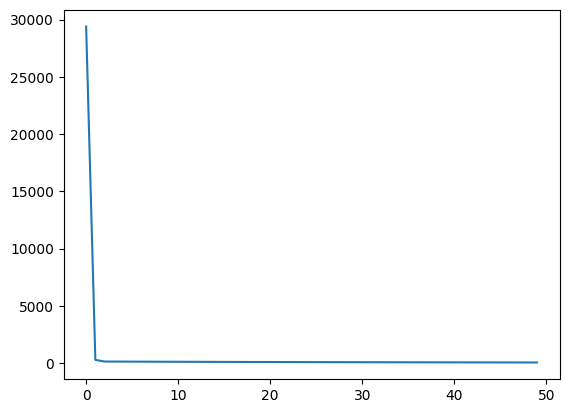

In [4]:
import numpy as np
import pandas as pd
 
x1 = np.random.randint(3, 12, 10)
x2 = np.random.randint(9, 18, 10)
x3 = np.random.randint(12, 20, 10)
y = x1 * 7 + 5 * x2 + 4 * x3
 
print(x1)
 
SHAPE = x1.shape[0]
print(x1.shape)
print(y.shape)
print(x1, x2, x3)
 
# NOTE: original notebook had `Shape` here (NameError). Fixed to `SHAPE`.
y = y.reshape(SHAPE, 1)
print(y)
 
X = np.array([x1, x2, x3])
print(X)
 
X = X.T
print(X)
 
lr = 0.0001
w = np.array([np.random.randn(1),
              np.random.randn(1),
              np.random.randn(1)])
print(w)
 
error_list = []
for i in range(50):
    y_pred = np.matmul(X, w)
    error = (y - y_pred) ** 2
    dEw1 = 2 * np.matmul((y - y_pred).T, (-X[:, 0].reshape(SHAPE, 1)))
    dEw2 = 2 * np.matmul((y - y_pred).T, (-X[:, 1].reshape(SHAPE, 1)))
    dEw3 = 2 * np.matmul((y - y_pred).T, (-X[:, 2].reshape(SHAPE, 1)))
    w[0][0] = w[0][0] - lr * dEw1.item()
    w[1][0] = w[1][0] - lr * dEw2.item()
    w[2][0] = w[2][0] - lr * dEw3.item()
    error_list.append(error.mean())
    print("value of w1", w[0][0], "value of w2", w[1][0], "value of w3", w[2][0])
 
plt.plot(error_list)
plt.show()